# Modelos generativos de texto con Transformer tipo LLaMA — Constitución Política de Colombia
**Punto 1:** generación a nivel de **carácter** · **Punto 2:** generación a nivel de **palabra**

**Estructura**
1. Setup, rutas y perfil de ejecución
2. Corpus (lectura y limpieza del PDF)
3. Bloques de la arquitectura (LLaMA vs GPT) + métricas + generación
4. Punto 1 — Char-level: entrenamiento, métricas, generación
5. Punto 2 — Word-level: entrenamiento, métricas, generación
6. Comparación final y conclusiones

> **Dónde ejecutarlo.** Pensado para **Linux nativo** (TensorFlow usa la GPU NVIDIA allí). Opciones:
> - **Linux con GPU NVIDIA** → `requirements_linux.txt` (ver `GUIA_LINUX.md`). El notebook detecta la GPU y usa el perfil `gpu` (3 semillas).
> - **Sin GPU** → perfil `cpu` automáticamente (ligero, 1 semilla).
> - **Colab** → perfil `gpu`; sube el PDF cuando lo pida.

## 1. Setup, rutas y perfil de ejecución
`PERFIL` controla el tamaño del modelo y el tiempo de entrenamiento:

In [ ]:
import os, sys, re, math, json, time, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import tensorflow as tf
for _g in tf.config.list_physical_devices("GPU"):          # memoria de GPU bajo demanda (evita ocupar toda la VRAM)
    try: tf.config.experimental.set_memory_growth(_g, True)
    except Exception: pass
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from pypdf import PdfReader

warnings.filterwarnings("ignore", message=".*build\\(\\) was called.*")   
keras.utils.set_random_seed(42)                                           # reproducibilidad

# ---------------- RUTAS (Linux local o Colab) ----------------
def buscar_carpeta_entregable():
    """Carpeta que contiene el PDF de la Constitución. Orden: variable de entorno ENTREGABLE_DIR -> carpeta
    del notebook -> sitios típicos del home -> (último recurso) una partición de Windows montada."""
    import glob
    cands = []
    if os.environ.get("ENTREGABLE_DIR"):
        cands.append(Path(os.environ["ENTREGABLE_DIR"]).expanduser())
    h = Path.home()
    cands += [Path.cwd(), Path.cwd().parent, h / "Entregable Transformers"]
    cands += [h / d / "IA Generativa" / "Entregable Transformers" for d in ("Escritorio", "Desktop", "Documentos", "Documents")]
    cands += [Path(p) for p in glob.glob("/media/*/*/Users/*/OneDrive/Escritorio/IA Generativa/Entregable Transformers")
                                + glob.glob("/mnt/*/Users/*/OneDrive/Escritorio/IA Generativa/Entregable Transformers")]
    for p in cands:
        if p.is_dir() and list(p.glob("Constituci*2024*.pdf")):
            return p
    raise FileNotFoundError("No encontré la carpeta con Constitución_2024.pdf. Abre el notebook desde esa carpeta "
                            "o define la variable de entorno ENTREGABLE_DIR con su ruta.")

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:                               # En Colab: se trabaja en /content y se sube el PDF
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pypdf"])
    RUTA = Path("/content")
    if not list(RUTA.glob("Constituci*2024*.pdf")):
        from google.colab import files
        print("Sube el PDF de la Constitución (Constitución_2024.pdf):"); files.upload()
else:
    RUTA = buscar_carpeta_entregable()
candidatos = list(RUTA.glob("Constituci*2024*.pdf"))
assert candidatos, f"No encontré el PDF de la Constitución en {RUTA}"
PDF_CONSTITUCION = candidatos[0]
SALIDAS = RUTA / "salidas"; SALIDAS.mkdir(exist_ok=True)     # modelos, tablas y gráficas se guardan aquí
print("Carpeta de trabajo:", RUTA)
print("PDF:", PDF_CONSTITUCION.name)

PERFIL = "gpu"
GPU = bool(tf.config.list_physical_devices("GPU"))
if PERFIL == "auto":
    PERFIL = "gpu" if GPU else "cpu"

PERFILES = {
    # c = char-level, w = word-level.
    # bloque = tamaño de los bloques del split (tokens); periodo = cada cuántos bloques hay validación (bloque%periodo==0)
    #   y test (bloque%periodo==periodo//2): periodo 20 -> 5 % / 5 %, periodo 10 -> 10 % / 10 %.
    # gen = tamaño de los textos generados y nº de muestras por configuración (se promedian las métricas).
    "prueba": dict(max_chars=40_000, n_seeds=1, gen=dict(chars=100, words=50, muestras=1),
        c=dict(d_model=64,  n_layers=2, n_heads=4, n_kv=2, dropout=0.10, len=64,  shift=8,  batch=64,  epochs=1,  lr=2e-3, bloque=512,  periodo=20, tie=False),
        w=dict(d_model=64,  n_layers=2, n_heads=4, n_kv=2, dropout=0.20, len=24,  shift=1,  batch=32,  epochs=1,  lr=2e-3, bloque=128,  periodo=10, tie=True)),
    "cpu": dict(max_chars=None, n_seeds=1, gen=dict(chars=600, words=200, muestras=2),
        c=dict(d_model=96,  n_layers=3, n_heads=4, n_kv=2, dropout=0.15, len=96,  shift=16, batch=64,  epochs=12, lr=2e-3, bloque=4096, periodo=20, tie=False),
        w=dict(d_model=128, n_layers=2, n_heads=4, n_kv=2, dropout=0.30, len=32,  shift=2,  batch=64,  epochs=10, lr=1.5e-3, bloque=1024, periodo=10, tie=True)),
    "gpu": dict(max_chars=None, n_seeds=3, gen=dict(chars=1500, words=400, muestras=3),
        # Con shift pequeño, UNA época = len/shift pasadas por el corpus (char: 128/4 = 32). Los modelos memorizaban en 3-4 épocas.
        # Ahora: shift mayor (menos solape), más dropout y weight decay, y más paciencia. Hipótesis: prueba antes con N_SEEDS = 1.
        c=dict(d_model=192, n_layers=4, n_heads=6, n_kv=2, dropout=0.25, len=128, shift=32, batch=128, epochs=60, lr=2e-3, bloque=4096, periodo=20, tie=False, wd=0.1, patience=5),
        # Word-level: el modelo anterior (1.76 M parámetros para ~80 mil tokens) sobreajustaba desde la época 1 -> más pequeño y regularizado.
        w=dict(d_model=128, n_layers=2, n_heads=4, n_kv=2, dropout=0.40, len=48,  shift=16, batch=64,  epochs=60, lr=1.5e-3, bloque=1024, periodo=10, tie=True, wd=0.1, patience=5)),
}
N_SEEDS = None          # None = usa las semillas del perfil (gpu: 3, cpu: 1)
P = PERFILES[PERFIL]
if N_SEEDS: P["n_seeds"] = N_SEEDS
_gpu_name = tf.config.experimental.get_device_details(tf.config.list_physical_devices("GPU")[0]).get("device_name", "GPU") if GPU else "—"
print(f"TensorFlow {tf.__version__} | GPU: {_gpu_name} | perfil: {PERFIL} | semillas: {P['n_seeds']}")

2026-10-20 18:25:42.557165: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 18:25:42.888121: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 18:25:43.023469: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 18:25:43.061759: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-20 18:25:43.312747: I tensorflow/core/platform/cpu_feature_guar

Carpeta de trabajo: /home/isabellap/Escritorio/Entregable Transformers
PDF: Constitución_2024.pdf
TensorFlow 2.17.0 | GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU | perfil: gpu | semillas: 3


I0000 00:00:1792538750.672802    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538750.939219    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538750.940948    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538751.035004    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

## 2. Corpus: Constitución Política de Colombia (PDF → texto limpio)
El PDF (255 páginas) es una edición con texto seleccionable. Se hace lo siguiente:
1. Se omiten las 20 primeras páginas (créditos e índice) y se empieza en el Preámbulo
2. Se eiminan los encabezados repetidos de cada página (título del libro, número de página, nombre del título constitucional, etc)
3. Se reconstruyen palabras partidas por fin de línea (`participa-\nción` = `participación`)
4. Se quitan las motas editoriales de reforma ("Inciso adicionado por el artículo 1° del Acto Legislativo…")
5. Se unen las líneas de un mismo párrafo y se conserva un salto de línea entre artículos, incisos y encabezados

In [ ]:
PAG_INICIO = 20     # índice (base 0) de la página donde empieza el Preámbulo

NOMBRE_LIBRO = "Constitución Política de Colombia"
RE_GUARDIANA = re.compile(r"^\s*(?:\d{1,3}\s*)?Guardiana de la integridad y supremacía de la Constitución\s*\d{0,3}\s*")
RE_PREFIJO = re.compile(r"Guardiana|Preámbulo|(?:TÍTULO|Título)\s+(?:[IVXL]+|TRANSITORIO):|^\s*\d{1,3}\b|\d{1,3}\s*$")

def limpiar_pagina(txt):
    """Quita el encabezado de cada página. Es robusto a la versión de pypdf 
        (que puede pegar el encabezado con la primera línea del texto)"""
    t = RE_GUARDIANA.sub("", txt)
    k = t.find(NOMBRE_LIBRO)
    if 0 <= k < 350:
        pref = t[:k].strip()
        if pref == "" or (RE_PREFIJO.search(pref) and not re.search(r"\.\s", pref)):
            t = t[k + len(NOMBRE_LIBRO):]
    return t.lstrip("\n ")

# Notas editoriales que dicen "Inciso adicionado por el artículo 1...."
NOTA = re.compile(
    r"(?:Inciso|Incisos|Parágrafo|Numeral|Literal|Aparte|Apartes|Expresión|Artículo|Título|Capítulo|Texto|Frase|Palabra|Palabras)s?"
    r"\s(?:[^.]|No\.){0,90}?\b(?:adicionad|modificad|derogad|subrogad|sustituid|declarad|suprimid|incluid|reformad|adicionó)\w*"
    r"(?:[^.]|No\.){0,200}?\d{4}\.\s*", re.I)

def unir_guiones(t):
    """Algunas versiones de pypdf dejan 'participa-ción' sin salto de línea. Se une si la palabra completa
    existe en el texto o si alguna de las dos mitades nunca aparece como palabra suelta;
    así se conservan guiones legítimos como 'político-administrativo'."""
    cnt = Counter(re.findall(r"\w+", re.sub(r"\w+-\w+", " ", t.lower())))   # palabras sueltas, sin las compuestas con guion
    def f(m):
        a, b = m.group(1), m.group(2)
        if cnt[(a + b).lower()] >= 1 or cnt[a.lower()] == 0 or cnt[b.lower()] == 0:
            return a + b
        return m.group(0)
    return re.sub(r"\b([a-záéíóúñü]{2,})-([a-záéíóúñü]{2,})\b", f, t, flags=re.I)

def es_encabezado(s):
    """Línea en MAYÚSCULAS (TÍTULO, CAPÍTULO, nombre del título…): debe quedar en su propia línea."""
    letras = [c for c in s if c.isalpha()]
    return len(letras) >= 3 and all(c.isupper() for c in letras) and len(s) < 120

def limpiar(raw):
    t = raw.replace("\u00ad", "")                                  # guiones blandos
    t = re.sub(r"Guardiana de la integridad y supremacía de la Constitución\s*\d{0,3}", " ", t)   # encabezado suelto
    t = re.sub(r"(?<=\w) ?-[ \t]*\n[ \t]*(?=[a-záéíóúñü])", "", t)             # palabras partidas "participa-\nción"
    t = NOTA.sub("", t)                                            # notas editoriales de reforma
    t = re.sub(r"(?:Modificado|Adicionado|Derogado|Subrogado|Sustituido)s? por el art[ií]culo(?:[^.]|No\.){0,140}?\d{4}\.\s*", "", t)
    t = re.sub(r"(?m)^\s*\d{1,3}\s*$", "", t)                      # números de página sueltos
    t = re.sub(r"<[^<>]{0,250}>", "", t)                           # marcas <Artículo modificado …>
    t = unir_guiones(re.sub(r"[ \t]+", " ", t))
    parrafos, act, prev_head = [], "", False
    for s in (l.strip() for l in t.split("\n")):
        if not s:
            continue
        cabeza = es_encabezado(s) or re.match(r"(ARTÍCULO|PARÁGRAFO|CAPÍTULO|TÍTULO)\b", s)
        corte = cabeza or prev_head or (act and act[-1] in ".:;!?" and s[0].isupper())
        if corte and act:
            parrafos.append(act); act = s
        else:
            act = (act + " " + s) if act else s
        prev_head = es_encabezado(s)
    if act:
        parrafos.append(act)
    return "\n".join(parrafos)

def leer_constitucion(path):
    paginas = PdfReader(str(path)).pages[PAG_INICIO:]
    return limpiar("\n".join(limpiar_pagina(p.extract_text() or "") for p in paginas))

CORPUS_TXT = SALIDAS / "corpus_constitucion.txt"
if CORPUS_TXT.exists():                      # cache: no vuelvas a leer el PDF cada vez
    corpus_completo = CORPUS_TXT.read_text(encoding="utf-8")
else:
    corpus_completo = leer_constitucion(PDF_CONSTITUCION)
    CORPUS_TXT.write_text(corpus_completo, encoding="utf-8")

corpus = corpus_completo[:P["max_chars"]] if P["max_chars"] else corpus_completo
corpus_lc = corpus.lower()      # minúsculas con Python (Á→á, Ó→ó…). Keras con standardize="lower" solo baja ASCII.
print(f"Caracteres: {len(corpus):,} | palabras ≈ {len(corpus.split()):,} | artículos: {len(re.findall(r'ARTÍCULO', corpus))}")
print("\n--- muestra ---\n" + corpus[1200:2000])

Caracteres: 454,507 | palabras ≈ 70,225 | artículos: 495

--- muestra ---
ia del interés general.
ARTÍCULO 2°. Son fines esenciales del Estado: servir a la comunidad, promover la prosperidad general y garantizar la efectividad de los principios, derechos y deberes consagrados en la Constitución; facilitar la participación de todos en las decisiones que los afectan y en la vida económica, política, administrativa y cultural de la Nación; defender la independencia nacional, mantener la integridad territorial y asegurar la convivencia pacífica y la vigencia de un orden justo.
Las autoridades de la República están instituidas para proteger a todas las personas residentes en Colombia, en su vida, honra, bienes, creencias, y demás derechos y libertades, y para asegurar el cumplimiento de los deberes sociales del Estado y de los particulares.
ARTÍCULO 3°. La soberanía 


## 3. Bloques de la arquitectura
`arch="llama"` → **RMSNorm** (pre-norm) + **RoPE** en Q y K + **SwiGLU** + **GQA** (`n_kv_heads < n_heads`).
`arch="gpt"` → LayerNorm + embedding posicional aprendido + FFN con GELU (baseline de la clase)

También se incluyen: `to_dataset` (ventanas deslizantes), `eval_lm` (loss, perplejidad, accuracy top‑1/top‑5), `generate_ids` (temperatura + top‑k) y `metricas_texto` (calidad del texto generado)

In [ ]:
# ---------- Bloques ----------
@keras.utils.register_keras_serializable(package="llm")
class RMSNorm(layers.Layer):
    """RMSNorm: x / sqrt(mean(x^2) + eps) * g  (sin centrar la media ni bias)."""
    def __init__(self, eps=1e-6, **kw):
        super().__init__(**kw); self.eps = eps
    def build(self, shape):
        self.g = self.add_weight(name="g", shape=(shape[-1],), initializer="ones")
    def call(self, x):
        rms = tf.math.rsqrt(tf.reduce_mean(tf.square(x), axis=-1, keepdims=True) + self.eps)
        return x * rms * self.g
    def get_config(self):
        return {**super().get_config(), "eps": self.eps}

def rope(x, base=10000.0):
    """RoPE sobre x de forma (B, H, T, Dh): rota pares de dimensiones según la posición."""
    T = tf.shape(x)[2]; Dh = x.shape[-1]
    inv_freq = 1.0 / (base ** (tf.range(0, Dh, 2, dtype=tf.float32) / Dh))   # (Dh/2,)
    ang = tf.cast(tf.range(T), tf.float32)[:, None] * inv_freq[None, :]      # (T, Dh/2)
    ang = tf.concat([ang, ang], axis=-1)                                      # (T, Dh)
    cos, sin = tf.cos(ang)[None, None], tf.sin(ang)[None, None]
    x1, x2 = x[..., : Dh // 2], x[..., Dh // 2:]
    rot = tf.concat([-x2, x1], axis=-1)
    return x * cos + rot * sin

@keras.utils.register_keras_serializable(package="llm")
class CausalSelfAttention(layers.Layer):
    """Atención causal. n_kv_heads < n_heads => Grouped-Query Attention (GQA).
    use_rope=True aplica RoPE a Q y K (LLaMA); False = atención estilo GPT."""
    def __init__(self, d_model, n_heads, n_kv_heads=None, use_rope=True, dropout=0.0, use_bias=False, **kw):
        super().__init__(**kw)
        self.d_model, self.n_heads = d_model, n_heads
        self.n_kv = n_kv_heads or n_heads
        self.use_rope, self.drop_rate, self.use_bias = use_rope, dropout, use_bias
        self.dh = d_model // n_heads
        self.wq = layers.Dense(n_heads * self.dh, use_bias=use_bias)
        self.wk = layers.Dense(self.n_kv * self.dh, use_bias=use_bias)
        self.wv = layers.Dense(self.n_kv * self.dh, use_bias=use_bias)
        self.wo = layers.Dense(d_model, use_bias=use_bias)
        self.drop = layers.Dropout(dropout)
    def call(self, x, training=False):
        B, T = tf.shape(x)[0], tf.shape(x)[1]
        q = tf.transpose(tf.reshape(self.wq(x), (B, T, self.n_heads, self.dh)), (0, 2, 1, 3))
        k = tf.transpose(tf.reshape(self.wk(x), (B, T, self.n_kv, self.dh)), (0, 2, 1, 3))
        v = tf.transpose(tf.reshape(self.wv(x), (B, T, self.n_kv, self.dh)), (0, 2, 1, 3))
        if self.use_rope:
            q, k = rope(q), rope(k)
        if self.n_kv != self.n_heads:                       # repetir K,V para cada grupo de queries
            rep = self.n_heads // self.n_kv
            k, v = tf.repeat(k, rep, axis=1), tf.repeat(v, rep, axis=1)
        s = tf.matmul(q, k, transpose_b=True) / math.sqrt(self.dh)
        mask = tf.linalg.band_part(tf.ones((T, T)), -1, 0)  # triangular inferior (causal)
        s = tf.where(mask[None, None] > 0, s, -1e9)
        a = self.drop(tf.nn.softmax(s, axis=-1), training=training)
        o = tf.reshape(tf.transpose(tf.matmul(a, v), (0, 2, 1, 3)), (B, T, self.n_heads * self.dh))
        return self.wo(o)
    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "n_heads": self.n_heads,
                "n_kv_heads": self.n_kv, "use_rope": self.use_rope, "dropout": self.drop_rate,
                "use_bias": self.use_bias}

@keras.utils.register_keras_serializable(package="llm")
class SwiGLU(layers.Layer):
    """FFN LLaMA: down( silu(gate(x)) * up(x) ). hidden ~ 8/3 * d para igualar parámetros del FFN clásico."""
    def __init__(self, d_model, hidden=None, **kw):
        super().__init__(**kw)
        self.d_model = d_model
        self.hidden = hidden or int(2 * 4 * d_model / 3 // 32 * 32) or 32
        self.gate = layers.Dense(self.hidden, use_bias=False)
        self.up = layers.Dense(self.hidden, use_bias=False)
        self.down = layers.Dense(d_model, use_bias=False)
    def call(self, x):
        return self.down(tf.nn.silu(self.gate(x)) * self.up(x))
    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "hidden": self.hidden}

@keras.utils.register_keras_serializable(package="llm")
class DecoderBlock(layers.Layer):
    """arch='llama': pre-RMSNorm + RoPE (+GQA) + SwiGLU.  arch='gpt': pre-LayerNorm + MHA + FFN GELU (baseline)."""
    def __init__(self, d_model, n_heads, n_kv_heads=None, arch="llama", dropout=0.1, **kw):
        super().__init__(**kw)
        self.cfg = dict(d_model=d_model, n_heads=n_heads, n_kv_heads=n_kv_heads, arch=arch, dropout=dropout)
        llama = arch == "llama"
        Norm = RMSNorm if llama else layers.LayerNormalization
        self.n1, self.n2 = Norm(), Norm()
        self.attn = CausalSelfAttention(d_model, n_heads, n_kv_heads if llama else None,
                                        use_rope=llama, dropout=dropout, use_bias=not llama)
        self.ffn = SwiGLU(d_model) if llama else keras.Sequential(
            [layers.Dense(4 * d_model, activation="gelu"), layers.Dense(d_model)])
        self.drop = layers.Dropout(dropout)
    def call(self, x, training=False):
        x = x + self.drop(self.attn(self.n1(x), training=training), training=training)
        x = x + self.drop(self.ffn(self.n2(x)), training=training)
        return x
    def get_config(self):
        return {**super().get_config(), **self.cfg}

@keras.utils.register_keras_serializable(package="llm")
class LearnedPositions(layers.Layer):
    """Embedding posicional aprendido (solo para el baseline GPT)."""
    def __init__(self, max_len, d_model, **kw):
        super().__init__(**kw); self.max_len, self.d_model = max_len, d_model
        self.emb = layers.Embedding(max_len, d_model)
    def call(self, x):
        return x + self.emb(tf.range(tf.shape(x)[1]))[None]
    def get_config(self):
        return {**super().get_config(), "max_len": self.max_len, "d_model": self.d_model}

@keras.utils.register_keras_serializable(package="llm")
class TokenEmbedding(layers.Layer):
    """Embedding con *weight tying*: la misma matriz sirve de entrada (token→vector) y de salida
    (vector→logits, con la traspuesta). Reduce parámetros y ayuda cuando hay pocos datos (word-level)."""
    def __init__(self, vocab_size, d_model, **kw):
        super().__init__(**kw); self.vocab_size, self.d_model = vocab_size, d_model
    def build(self, input_shape):
        self.emb = self.add_weight(name="emb", shape=(self.vocab_size, self.d_model),
                                   initializer=keras.initializers.RandomNormal(stddev=self.d_model ** -0.5))
        self.bias = self.add_weight(name="bias", shape=(self.vocab_size,), initializer="zeros")
    def call(self, x, logits=False):
        if logits:
            return tf.nn.softmax(tf.matmul(x, self.emb, transpose_b=True) + self.bias)
        return tf.gather(self.emb, x)
    def get_config(self):
        return {**super().get_config(), "vocab_size": self.vocab_size, "d_model": self.d_model}

def build_lm(vocab_size, max_len, d_model=128, n_layers=4, n_heads=4, n_kv_heads=None,
             arch="llama", dropout=0.1, tie=False):
    inp = keras.Input(shape=(None,), dtype="int32")
    if tie:
        tok = TokenEmbedding(vocab_size, d_model); x = tok(inp)
    else:
        x = layers.Embedding(vocab_size, d_model)(inp)
    if arch == "gpt":
        x = LearnedPositions(max_len, d_model)(x)
    x = layers.Dropout(dropout)(x)
    for _ in range(n_layers):
        x = DecoderBlock(d_model, n_heads, n_kv_heads, arch, dropout)(x)
    x = (RMSNorm() if arch == "llama" else layers.LayerNormalization())(x)
    out = tok(x, logits=True) if tie else layers.Dense(vocab_size, activation="softmax")(x)
    return keras.Model(inp, out, name=f"lm_{arch}")

# ---------- Datos: split por BLOQUES intercalados ----------
# Así validación y test provienen de TODA la Constitución (no solo del final) y ninguna ventana cruza bloques
def ventanas(seq, length, shift, bloque, destino, periodo=20):
    """Ventanas de length+1 tokens dentro de un mismo bloque. Devuelve (X, Y): entrada y siguiente token."""
    seq = np.asarray(seq)
    starts = np.arange(0, len(seq) - length - 1, shift)
    b0, b1 = starts // bloque, (starts + length) // bloque
    tipo = np.where(b0 % periodo == 0, "val", np.where(b0 % periodo == periodo // 2, "test", "train"))
    sel = starts[(b0 == b1) & (tipo == destino)]
    W = seq[sel[:, None] + np.arange(length + 1)[None, :]].astype("int32")
    return W[:, :-1], W[:, 1:]

def to_ds(XY, batch, shuffle=False, seed=None):
    X, Y = XY
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=seed)
    return ds.batch(batch).prefetch(1)

def mascara_train(n_tokens, bloque, periodo=20):
    """True para los tokens que caen en bloques de entrenamiento."""
    b = (np.arange(n_tokens) // bloque) % periodo
    return (b != 0) & (b != periodo // 2)

# ---------- Métricas del modelo de lenguaje ----------
def eval_lm(model, ds):
    """Devuelve loss (nats/token), perplejidad, accuracy top-1 y top-5 sobre un dataset."""
    loss_fn = keras.losses.SparseCategoricalCrossentropy(reduction="none")
    nll = n = c1 = c5 = 0
    for x, y in ds:
        y = tf.cast(y, tf.int32)
        p = model(x, training=False)
        nll += float(tf.reduce_sum(loss_fn(y, p)))
        n += int(tf.size(y))
        c1 += float(tf.reduce_sum(tf.cast(tf.equal(tf.argmax(p, -1, output_type=tf.int32), y), tf.float32)))
        c5 += float(tf.reduce_sum(tf.cast(tf.math.in_top_k(tf.reshape(y, [-1]), tf.reshape(p, [-1, p.shape[-1]]), 5), tf.float32)))
    loss = nll / n
    return dict(nll_total=nll, n_tokens=n, loss=loss, ppl=math.exp(loss), acc=c1 / n, top5=c5 / n)

# ---------- Generación (temperatura + top-k) ----------
def generate_ids(model, prompt_ids, n_new, context, temperature=0.8, top_k=None, seed=None,
                 bloquear=(), rep_penalty=1.0, rep_ventana=64):
    """Muestreo con temperatura + top-k. `bloquear`: ids que nunca se muestrean (p. ej. <pad>, <unk>).
    `rep_penalty` > 1 penaliza los tokens vistos en las últimas `rep_ventana` posiciones (evita bucles)."""
    rng = np.random.default_rng(seed)
    ids = list(prompt_ids)
    for _ in range(n_new):
        x = np.array([ids[-context:]], dtype="int32")
        p = model(x, training=False)[0, -1].numpy().astype("float64")
        logits = np.log(p + 1e-12) / max(temperature, 1e-4)
        if rep_penalty != 1.0:
            for t in set(ids[-rep_ventana:]):
                logits[t] = logits[t] * rep_penalty if logits[t] < 0 else logits[t] / rep_penalty
        if len(bloquear):
            logits[list(bloquear)] = -np.inf
        if top_k:
            kth = np.sort(logits)[-top_k]
            logits = np.where(logits < kth, -np.inf, logits)
        pr = np.exp(logits - logits.max()); pr /= pr.sum()
        ids.append(int(rng.choice(len(pr), p=pr)))
    return ids

# ---------- Calidad del texto generado (char y word) ----------
PAL_CORPUS = re.findall(r"\w+", corpus_lc)
PALABRAS_CORPUS = set(PAL_CORPUS)
GRAMAS4 = set(zip(PAL_CORPUS, PAL_CORPUS[1:], PAL_CORPUS[2:], PAL_CORPUS[3:]))

def metricas_texto(texto, nivel):
    """distinct1/2: diversidad. rep_3gram: trigramas repetidos dentro del texto generado.
    copia_4gram: % de 4-gramas de palabras que aparecen LITERALMENTE en la Constitución (memorización).
    char -> palabras_validas: % de palabras que existen en la Constitución (ortografía).
    word -> pct_unk: % de tokens generados que son <unk> (las palabras 'válidas' lo son por construcción)."""
    extra = {}
    if nivel == "word":
        toks = tokenizar(texto)
        extra["pct_unk"] = round(toks.count("<unk>") / max(len(toks), 1), 3)
        texto = texto.replace("<unk>", " ")
    pal = re.findall(r"\w+", texto.lower())
    if len(pal) < 5:
        return dict(distinct1=np.nan, distinct2=np.nan, rep_3gram=np.nan, copia_4gram=np.nan, **extra)
    bi, tri, cu = list(zip(pal, pal[1:])), list(zip(pal, pal[1:], pal[2:])), list(zip(pal, pal[1:], pal[2:], pal[3:]))
    if nivel == "char":
        extra["palabras_validas"] = round(float(np.mean([w in PALABRAS_CORPUS for w in pal])), 3)
    return dict(distinct1=round(len(set(pal)) / len(pal), 3), distinct2=round(len(set(bi)) / len(bi), 3),
                rep_3gram=round(1 - len(set(tri)) / len(tri), 3),
                copia_4gram=round(float(np.mean([g in GRAMAS4 for g in cu])), 3), **extra)

# ---------- Entrenamiento (varias semillas) ----------
def entrenar(nombre, arch, vocab, max_len, XY_train, XY_valid, cfg, seed):
    keras.utils.set_random_seed(seed)
    train = to_ds(XY_train, cfg["batch"], shuffle=True, seed=seed)
    valid = to_ds(XY_valid, cfg["batch"])
    m = build_lm(vocab, max_len, d_model=cfg["d_model"], n_layers=cfg["n_layers"], n_heads=cfg["n_heads"],
                 n_kv_heads=cfg["n_kv"] if arch == "llama" else None, arch=arch, dropout=cfg["dropout"],
                 tie=cfg.get("tie", False))
    m.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.AdamW(cfg["lr"], weight_decay=cfg.get("wd", 0.01), clipnorm=1.0), metrics=["accuracy"])
    cbs = [keras.callbacks.EarlyStopping(patience=cfg.get("patience", 3), restore_best_weights=True, monitor="val_loss"),
           keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1, min_lr=1e-5)]
    t0 = time.time()
    h = m.fit(train, validation_data=valid, epochs=cfg["epochs"], callbacks=cbs, verbose=2)
    print(f"{nombre} (semilla {seed}): {m.count_params():,} parámetros, {time.time()-t0:.0f}s, "
          f"mejor época {int(np.argmin(h.history['val_loss']))+1}")
    return m, h.history

def entrenar_todo(nivel, vocab, max_len, XY_train, XY_valid, cfg):
    runs = {}
    for arch, nombre in [("llama", "LLaMA"), ("gpt", "GPT")]:
        runs[nombre] = [entrenar(f"{nombre}-{nivel}", arch, vocab, max_len, XY_train, XY_valid, cfg, seed=42 + s)
                        for s in range(P["n_seeds"])]
    return runs

def resumen(rs, claves):
    """rs: lista de dicts (una por semilla). Devuelve media y desviación de cada clave."""
    out = {}
    for k in claves:
        v = np.array([r[k] for r in rs], dtype=float)
        out[k] = v.mean(); out[k + "_std"] = v.std(ddof=1) if len(v) > 1 else np.nan
    return out

def veredicto(rs_llama, rs_gpt, clave):
    """Compara dos arquitecturas en una métrica (menor = mejor). Con varias semillas usa 2 desviaciones;
    con una sola semilla exige > 1 % de diferencia relativa. Si no, declara empate técnico."""
    a = np.array([r[clave] for r in rs_llama]); b = np.array([r[clave] for r in rs_gpt])
    dif = a.mean() - b.mean(); ref = max(a.mean(), b.mean())
    umbral = 2 * max(a.std(ddof=1), b.std(ddof=1)) if min(len(a), len(b)) > 1 else 0.01 * ref
    if abs(dif) <= umbral:
        return f"EMPATE técnico (LLaMA {a.mean():.3f} vs GPT {b.mean():.3f}; dif. {abs(dif)/ref*100:.1f}% ≤ umbral de ruido)"
    return f"{'LLaMA' if dif < 0 else 'GPT'} es mejor ({a.mean():.3f} vs {b.mean():.3f}; dif. {abs(dif)/ref*100:.1f}%)"

def curvas(runs, titulo, archivo):
    """Curvas de la primera semilla de cada arquitectura (train punteado, validación continua)."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for k, lst in runs.items():
        h = lst[0][1]
        ax[0].plot(h["loss"], "--", label=f"{k} train"); ax[0].plot(h["val_loss"], label=f"{k} val")
        ax[1].plot(h["val_accuracy"], label=k)
    ax[0].set_title(f"{titulo}: loss"); ax[1].set_title("accuracy validación")
    for a in ax: a.set_xlabel("época"); a.legend()
    plt.tight_layout(); plt.savefig(SALIDAS / archivo, dpi=130); plt.show()

def convergencia(runs):
    """Velocidad de convergencia (media sobre semillas)."""
    f = {k: dict(val_loss_ep1=np.mean([h["val_loss"][0] for _, h in lst]),
                 mejor_val_loss=np.mean([min(h["val_loss"]) for _, h in lst]),
                 mejor_epoca=np.mean([int(np.argmin(h["val_loss"])) + 1 for _, h in lst]))
         for k, lst in runs.items()}
    return pd.DataFrame(f).T

## 4. PUNTO 1 — Generación a nivel de carácter
### 4.1 Tokenización y datasets
Cada **carácter** es un token;
El texto ya está en minúsculas (hecho en Python) y se usa `standardize=None`, así `Á/Ó/Í…` no quedan como símbolos aparte; 
Split por bloques intercalados 90 / 5 / 5 % 

In [4]:
text_vec_layer = keras.layers.TextVectorization(split="character", standardize=None)
text_vec_layer.adapt([corpus_lc])
vocab_c = text_vec_layer.get_vocabulary()
encoded = (text_vec_layer([corpus_lc])[0] - 2).numpy().astype("int32")      # descartamos pad (0) y unk (1)
n_chars_vocab = text_vec_layer.vocabulary_size() - 2
print("Caracteres distintos:", n_chars_vocab, "| Total de caracteres:", len(encoded))
print("Vocabulario:", repr("".join(vocab_c[2:])))
assert not any(ch.isupper() for ch in vocab_c[2:]), "quedaron mayúsculas en el vocabulario"

C = P["c"]; LEN_C = C["len"]
train_c = ventanas(encoded, LEN_C, C["shift"], C["bloque"], "train", C["periodo"])
valid_c = ventanas(encoded, LEN_C, LEN_C,     C["bloque"], "val", C["periodo"])
test_c  = to_ds(ventanas(encoded, LEN_C, LEN_C, C["bloque"], "test", C["periodo"]), C["batch"])
print("ventanas train/valid/test:", len(train_c[0]), len(valid_c[0]), sum(1 for _ in test_c.unbatch()), "| contexto:", LEN_C)

I0000 00:00:1792538751.569676    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538751.571739    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538751.573508    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792538751.699814    5300 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Caracteres distintos: 62 | Total de caracteres: 454507
Vocabulario: ' eaoisrnlcdtupmgb,y.vóáfíqj\nhz1ú2xé03ñ95467);8(°:-*%“”º"/—ük]['
ventanas train/valid/test: 12276 186 185 | contexto: 128


2026-10-20 18:25:52.561910: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### 4.2 Modelos: LLaMA vs GPT (varias semillas)
Mismos hiperparámetros en ambos. Con `n_seeds > 1` cada arquitectura se entrena varias veces y se reporta **media ± desviación**.

In [ ]:
runs_c = entrenar_todo("char", n_chars_vocab, LEN_C, train_c, valid_c, C)
models_c = {k: v[0][0] for k, v in runs_c.items()}      # primera semilla, para generar y guardar

Epoch 1/60


/home/isabellap/Escritorio/Entregable Transformers/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792538771.042968    5373 service.cc:146] XLA service 0x7c7cb400a2b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792538771.043018    5373 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2026-10-20 18:26:11.503595: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1792538772.385774    5373 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/Sp

96/96 - 140s - 1s/step - accuracy: 0.2466 - loss: 2.5444 - val_accuracy: 0.3899 - val_loss: 1.9692 - learning_rate: 0.0020
Epoch 2/60
96/96 - 10s - 107ms/step - accuracy: 0.4320 - loss: 1.8260 - val_accuracy: 0.5467 - val_loss: 1.4695 - learning_rate: 0.0020
Epoch 3/60
96/96 - 10s - 106ms/step - accuracy: 0.5400 - loss: 1.4792 - val_accuracy: 0.6163 - val_loss: 1.2410 - learning_rate: 0.0020
Epoch 4/60
96/96 - 10s - 106ms/step - accuracy: 0.5922 - loss: 1.3040 - val_accuracy: 0.6457 - val_loss: 1.1397 - learning_rate: 0.0020
Epoch 5/60
96/96 - 10s - 107ms/step - accuracy: 0.6205 - loss: 1.2058 - val_accuracy: 0.6633 - val_loss: 1.0798 - learning_rate: 0.0020
Epoch 6/60
96/96 - 10s - 107ms/step - accuracy: 0.6390 - loss: 1.1423 - val_accuracy: 0.6762 - val_loss: 1.0372 - learning_rate: 0.0020
Epoch 7/60
96/96 - 10s - 107ms/step - accuracy: 0.6527 - loss: 1.0957 - val_accuracy: 0.6851 - val_loss: 1.0052 - learning_rate: 0.0020
Epoch 8/60
96/96 - 10s - 107ms/step - accuracy: 0.6629 - loss

W0000 00:00:1792539293.467881    5372 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792539320.199972    5369 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792539337.480935    5369 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792539340.390903    5373 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


96/96 - 61s - 639ms/step - accuracy: 0.2152 - loss: 2.6428 - val_accuracy: 0.3225 - val_loss: 2.1585 - learning_rate: 0.0020
Epoch 2/60
96/96 - 10s - 107ms/step - accuracy: 0.3913 - loss: 1.9526 - val_accuracy: 0.5177 - val_loss: 1.5659 - learning_rate: 0.0020
Epoch 3/60
96/96 - 10s - 107ms/step - accuracy: 0.5142 - loss: 1.5592 - val_accuracy: 0.6027 - val_loss: 1.2919 - learning_rate: 0.0020
Epoch 4/60
96/96 - 10s - 107ms/step - accuracy: 0.5803 - loss: 1.3463 - val_accuracy: 0.6409 - val_loss: 1.1595 - learning_rate: 0.0020
Epoch 5/60
96/96 - 10s - 107ms/step - accuracy: 0.6153 - loss: 1.2267 - val_accuracy: 0.6635 - val_loss: 1.0846 - learning_rate: 0.0020
Epoch 6/60
96/96 - 10s - 107ms/step - accuracy: 0.6364 - loss: 1.1537 - val_accuracy: 0.6754 - val_loss: 1.0404 - learning_rate: 0.0020
Epoch 7/60
96/96 - 10s - 107ms/step - accuracy: 0.6512 - loss: 1.1021 - val_accuracy: 0.6861 - val_loss: 1.0017 - learning_rate: 0.0020
Epoch 8/60
96/96 - 10s - 107ms/step - accuracy: 0.6627 - lo

...

96/96 - 66s - 690ms/step - accuracy: 0.2293 - loss: 2.5968 - val_accuracy: 0.3485 - val_loss: 2.0468 - learning_rate: 0.0020
Epoch 2/60
96/96 - 10s - 107ms/step - accuracy: 0.4093 - loss: 1.8879 - val_accuracy: 0.5287 - val_loss: 1.5195 - learning_rate: 0.0020
Epoch 3/60
96/96 - 10s - 107ms/step - accuracy: 0.5242 - loss: 1.5255 - val_accuracy: 0.6100 - val_loss: 1.2655 - learning_rate: 0.0020
Epoch 4/60
96/96 - 10s - 107ms/step - accuracy: 0.5868 - loss: 1.3237 - val_accuracy: 0.6442 - val_loss: 1.1423 - learning_rate: 0.0020
Epoch 5/60
96/96 - 10s - 107ms/step - accuracy: 0.6194 - loss: 1.2116 - val_accuracy: 0.6683 - val_loss: 1.0673 - learning_rate: 0.0020
Epoch 6/60
96/96 - 10s - 107ms/step - accuracy: 0.6404 - loss: 1.1391 - val_accuracy: 0.6811 - val_loss: 1.0205 - learning_rate: 0.0020
Epoch 7/60
96/96 - 10s - 108ms/step - accuracy: 0.6551 - loss: 1.0877 - val_accuracy: 0.6890 - val_loss: 0.9929 - learning_rate: 0.0020
Epoch 8/60
96/96 - 10s - 108ms/step - accuracy: 0.6669 - lo

W0000 00:00:1792540231.122721    5369 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
2026-10-20 18:50:39.237592: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11329', 228 bytes spill stores, 196 bytes spill loads

2026-10-20 18:50:41.562709: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_16153', 4 bytes spill stores, 4 bytes spill loads

2026-10-20 18:50:42.893747: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_14968', 2588 bytes spill stores, 2572 bytes spill loads

2026-10-20 18:50:43.657805: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393

96/96 - 97s - 1s/step - accuracy: 0.1550 - loss: 2.9698 - val_accuracy: 0.2310 - val_loss: 2.5104 - learning_rate: 0.0020
Epoch 2/60
96/96 - 11s - 115ms/step - accuracy: 0.2496 - loss: 2.3930 - val_accuracy: 0.2867 - val_loss: 2.2335 - learning_rate: 0.0020
Epoch 3/60
96/96 - 11s - 114ms/step - accuracy: 0.2799 - loss: 2.2448 - val_accuracy: 0.3170 - val_loss: 2.1470 - learning_rate: 0.0020
Epoch 4/60
96/96 - 11s - 113ms/step - accuracy: 0.3166 - loss: 2.1447 - val_accuracy: 0.3950 - val_loss: 1.9133 - learning_rate: 0.0020
Epoch 5/60
96/96 - 11s - 114ms/step - accuracy: 0.3902 - loss: 1.9323 - val_accuracy: 0.4831 - val_loss: 1.6255 - learning_rate: 0.0020
Epoch 6/60
96/96 - 11s - 115ms/step - accuracy: 0.4615 - loss: 1.7064 - val_accuracy: 0.5500 - val_loss: 1.4358 - learning_rate: 0.0020
Epoch 7/60
96/96 - 11s - 116ms/step - accuracy: 0.5163 - loss: 1.5367 - val_accuracy: 0.5984 - val_loss: 1.2896 - learning_rate: 0.0020
Epoch 8/60
96/96 - 11s - 116ms/step - accuracy: 0.5563 - loss:

W0000 00:00:1792540918.696528    5367 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792540950.968468    5369 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792540972.716451    5369 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1792540976.413218    5371 assert_op.cc:38] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


96/96 - 77s - 807ms/step - accuracy: 0.1369 - loss: 3.0706 - val_accuracy: 0.1514 - val_loss: 2.9549 - learning_rate: 0.0020
Epoch 2/60
96/96 - 11s - 115ms/step - accuracy: 0.2067 - loss: 2.6282 - val_accuracy: 0.2734 - val_loss: 2.3229 - learning_rate: 0.0020
Epoch 3/60
96/96 - 11s - 115ms/step - accuracy: 0.2665 - loss: 2.2992 - val_accuracy: 0.2884 - val_loss: 2.2099 - learning_rate: 0.0020
Epoch 4/60
96/96 - 11s - 114ms/step - accuracy: 0.2873 - loss: 2.2178 - val_accuracy: 0.3324 - val_loss: 2.0910 - learning_rate: 0.0020
Epoch 5/60
96/96 - 11s - 115ms/step - accuracy: 0.3302 - loss: 2.1024 - val_accuracy: 0.4167 - val_loss: 1.8545 - learning_rate: 0.0020
Epoch 6/60
96/96 - 11s - 115ms/step - accuracy: 0.4029 - loss: 1.8887 - val_accuracy: 0.5044 - val_loss: 1.5829 - learning_rate: 0.0020
Epoch 7/60
96/96 - 11s - 115ms/step - accuracy: 0.4746 - loss: 1.6669 - val_accuracy: 0.5654 - val_loss: 1.3919 - learning_rate: 0.0020
Epoch 8/60
96/96 - 11s - 115ms/step - accuracy: 0.5269 - lo

### 4.3 Curvas y velocidad de convergencia
La ventaja defendible de LLaMA suele estar en **cuántas épocas necesita**, no solo en el valor final.

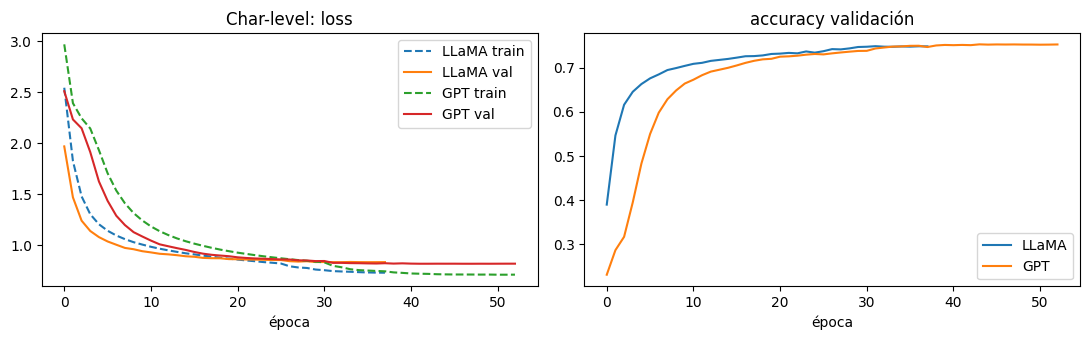

,val_loss_ep1,mejor_val_loss,mejor_epoca
LLaMA,2.058177,0.831540,34.0
GPT,2.713557,0.828924,46.0


In [6]:
curvas(runs_c, "Char-level", "curvas_char.png")
conv_c = convergencia(runs_c); conv_c.to_csv(SALIDAS / "convergencia_char.csv"); conv_c

### 4.4 Métricas en test
- **BPC** (bits por carácter) = loss / ln 2 — métrica estándar a nivel de carácter; **perplejidad** = exp(loss).
- Accuracy top‑1 y top‑5 del siguiente carácter.
- Media ± desviación entre semillas.

In [7]:
res_c = {}
for k, lst in runs_c.items():
    rs = []
    for m, _ in lst:
        r = eval_lm(m, test_c); r["bpc"] = r["loss"] / math.log(2); r["params"] = m.count_params(); rs.append(r)
    res_c[k] = rs
df_c = pd.DataFrame({k: resumen(rs, ["params", "loss", "ppl", "bpc", "acc", "top5"]) for k, rs in res_c.items()}).T
df_c["n_semillas"] = P["n_seeds"]
df_c.to_csv(SALIDAS / "metricas_char.csv")
df_c.round(4)

2026-10-20 19:22:35.029305: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-20 19:22:35.967043: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,params,params_std,loss,loss_std,ppl,ppl_std,bpc,bpc_std,acc,acc_std,top5,top5_std,n_semillas
LLaMA,1598462.0,0.0,0.8691,0.0022,2.3848,0.0052,1.2539,0.0032,0.7398,0.0034,0.9367,0.0002,3
GPT,1828286.0,0.0,0.8641,0.0042,2.3730,0.0099,1.2467,0.0060,0.7397,0.0034,0.9371,0.0010,3


### 4.5 Generación y calidad del texto
Se generan textos largos (varios cientos de palabras) y varias muestras por configuración, y se promedian las métricas. Se miden **% de palabras válidas** (ortografía: ¿existen en la Constitución?), **diversidad**, **repetición** de trigramas y **copia_4gram** (% de 4‑gramas copiados literalmente del corpus = memorización). Ojo: con T baja el modelo tiende a copiar; con T alta inventa.

In [8]:
c2i = {c: i - 2 for i, c in enumerate(vocab_c) if i >= 2}      # carácter -> id
def enc_c(s):  return [c2i[ch] for ch in s.lower() if ch in c2i]
def dec_c(ids): return "".join(vocab_c[i + 2] for i in ids)

prompt_c = "artículo 1°. colombia es un estado"
GEN = P["gen"]
AJUSTES = [(0.5, 10), (0.8, 20), (1.1, None)]       # (temperatura, top_k)

def generar_y_medir(models, enc, dec, prompt, n_new, ctx, nivel, muestras, **gen_kw):
    """Genera `muestras` textos por modelo y ajuste; imprime el primero y PROMEDIA las métricas de todos
    (con textos cortos las métricas de diversidad/copia son muy ruidosas)."""
    filas = []
    for nombre, m in models.items():
        for T, K in AJUSTES:
            ms = []
            for sm in range(muestras):
                out = generate_ids(m, enc(prompt), n_new, ctx, temperature=T, top_k=K, seed=7 + sm, **gen_kw)
                if sm == 0:
                    print(f"\n===== {nombre} | T={T} top_k={K} | muestra 1 de {muestras} =====\n{dec(out)}")
                ms.append(metricas_texto(dec(out[len(enc(prompt)):]), nivel))
            filas.append(dict(modelo=nombre, T=T, top_k=K, muestras=muestras,
                              **{k: round(float(np.nanmean([x[k] for x in ms])), 3) for k in ms[0]}))
    return pd.DataFrame(filas)

df_gen_c = generar_y_medir(models_c, enc_c, dec_c, prompt_c, GEN["chars"], LEN_C, "char", GEN["muestras"])
df_gen_c.to_csv(SALIDAS / "generacion_char.csv", index=False)
df_gen_c


===== LLaMA | T=0.5 top_k=10 | muestra 1 de 3 =====
artículo 1°. colombia es un estado promoverá la información de la estructura y con las rentas del sistema general de regalías.
artículo 147. la corte constitucional, mediante sentencia c-677 de 2016, m.p . luis guillermo guerrero pérez, así como el congreso de la república.
artículo 140. la ley reglamentará las medidas del sistema general de participaciones de los ciudadanos extraordinarios con personería jurídica a la gestión de los servicios públicos de las conductas punibles por la corte constitucional, mediante sentencia c-2044 de 2017, m.p . luis guillermo guerrero pérez, con el artículo 1° del acto legislativo 2 de 2017.
artículo transitorio 43. la administración de las rentas y ley de apropiaciones de la comisión permanente de la corte constitucional en el sistema general de participaciones de la comisión penal de los miembros de la fuerza pública y el contralor general de la nación en el acto legislativo 1 de 2017.
artículo t

,modelo,T,top_k,muestras,distinct1,distinct2,rep_3gram,copia_4gram,palabras_validas
0,LLaMA,0.5,10.0,3,0.416,0.730,0.131,0.371,0.995
1,LLaMA,0.8,20.0,3,0.521,0.877,0.034,0.254,0.993
2,LLaMA,1.1,NaN,3,0.611,0.952,0.003,0.107,0.959
3,GPT,0.5,10.0,3,0.483,0.798,0.087,0.433,0.999
4,GPT,0.8,20.0,3,0.547,0.871,0.043,0.306,0.999
5,GPT,1.1,NaN,3,0.594,0.925,0.017,0.190,0.961


In [ ]:
# Guardar el modelo (las capas están registradas con @register_keras_serializable)
models_c["LLaMA"].save(SALIDAS / "char_llama_constitucion.keras")
json.dump(vocab_c, open(SALIDAS / "vocab_char.json", "w", encoding="utf-8"), ensure_ascii=False)

## 5. PUNTO 2 — Generación a nivel de palabra
Cambia **solo la tokenización**: palabras y signos de puntuación como tokens y `<unk>` para palabras raras. 


### 5.1 Tokenización por palabra

In [10]:
def tokenizar(t):
    """Minúsculas; el salto de línea se vuelve el token <nl>; palabras y signos de puntuación son tokens."""
    t = t.lower().replace("<unk>", "§").replace("\n", " <nl> ")
    return [("<unk>" if x == "§" else x) for x in re.findall(r"<nl>|§|\w+|[^\w\s]", t)]

tokens = tokenizar(corpus_lc)
W = P["w"]; LEN_W = W["len"]
es_train = mascara_train(len(tokens), W["bloque"], W["periodo"])

MIN_FREQ = 2
freq = Counter(t for t, tr in zip(tokens, es_train) if tr)                      # <- solo bloques de entrenamiento
vocab_w = ["<pad>", "<unk>"] + [w for w, c in freq.most_common() if c >= MIN_FREQ]
w2i = {w: i for i, w in enumerate(vocab_w)}
V = len(vocab_w)
ids_w = np.array([w2i.get(w, 1) for w in tokens], dtype="int32")
print(f"Total de tokens: {len(tokens)} | vocabulario (solo train, freq>={MIN_FREQ}): {V}")
print(f"% <unk> en train: {100*np.mean(ids_w[es_train]==1):.2f}% | en val+test: {100*np.mean(ids_w[~es_train]==1):.2f}%")

train_w = ventanas(ids_w, LEN_W, W["shift"], W["bloque"], "train", W["periodo"])
valid_w = ventanas(ids_w, LEN_W, LEN_W,      W["bloque"], "val", W["periodo"])
test_w  = to_ds(ventanas(ids_w, LEN_W, LEN_W, W["bloque"], "test", W["periodo"]), W["batch"])
print("ventanas train/valid/test:", len(train_w[0]), len(valid_w[0]), sum(1 for _ in test_w.unbatch()), "| contexto:", LEN_W)
CHARS_POR_TOKEN = len(corpus_lc) / len(tokens)          # caracteres REALES por token (incluye espacios y saltos de línea)
print(f"Caracteres reales por token: {CHARS_POR_TOKEN:.2f}")

Total de tokens: 79828 | vocabulario (solo train, freq>=2): 2982
% <unk> en train: 3.87% | en val+test: 8.39%
ventanas train/valid/test: 3780 163 163 | contexto: 48
Caracteres reales por token: 5.69


2026-10-20 20:14:57.490434: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### 5.2 Entrenamiento

In [11]:
runs_w = entrenar_todo("word", V, LEN_W, train_w, valid_w, W)
models_w = {k: v[0][0] for k, v in runs_w.items()}

Epoch 1/60


/home/isabellap/Escritorio/Entregable Transformers/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-20 20:15:15.271294: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4120', 300 bytes spill stores, 300 bytes spill loads

2026-10-20 20:15:15.371427: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10', 316 bytes spill stores, 268 bytes spill loads

2026-10-20 20:15:15.913409: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory i

60/60 - 102s - 2s/step - accuracy: 0.0541 - loss: 6.2806 - val_accuracy: 0.0831 - val_loss: 5.4978 - learning_rate: 0.0015
Epoch 2/60
60/60 - 1s - 15ms/step - accuracy: 0.0761 - loss: 5.7412 - val_accuracy: 0.1140 - val_loss: 5.3447 - learning_rate: 0.0015
Epoch 3/60
60/60 - 1s - 15ms/step - accuracy: 0.1101 - loss: 5.5158 - val_accuracy: 0.1396 - val_loss: 5.0297 - learning_rate: 0.0015
Epoch 4/60
60/60 - 1s - 15ms/step - accuracy: 0.1286 - loss: 5.2361 - val_accuracy: 0.1520 - val_loss: 4.8424 - learning_rate: 0.0015
Epoch 5/60
60/60 - 1s - 15ms/step - accuracy: 0.1424 - loss: 5.0208 - val_accuracy: 0.1720 - val_loss: 4.6398 - learning_rate: 0.0015
Epoch 6/60
60/60 - 1s - 15ms/step - accuracy: 0.1539 - loss: 4.8237 - val_accuracy: 0.1709 - val_loss: 4.5187 - learning_rate: 0.0015
Epoch 7/60
60/60 - 1s - 15ms/step - accuracy: 0.1654 - loss: 4.6630 - val_accuracy: 0.1911 - val_loss: 4.3881 - learning_rate: 0.0015
Epoch 8/60
60/60 - 1s - 15ms/step - accuracy: 0.1776 - loss: 4.5316 - val

2026-10-20 20:19:44.651533: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_8138', 260 bytes spill stores, 260 bytes spill loads

2026-10-20 20:19:46.389189: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4', 92 bytes spill stores, 92 bytes spill loads

2026-10-20 20:19:46.399247: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4', 568 bytes spill stores, 532 bytes spill loads

2026-10-20 20:19:49.123766: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6175', 244 bytes spill stores, 212 bytes spill loads

2026-10-20 20:19:51.571034: I external/local_xla/xla/stream_

60/60 - 71s - 1s/step - accuracy: 0.0670 - loss: 6.0791 - val_accuracy: 0.0924 - val_loss: 5.4156 - learning_rate: 0.0015
Epoch 2/60
60/60 - 1s - 16ms/step - accuracy: 0.1100 - loss: 5.5303 - val_accuracy: 0.1394 - val_loss: 4.9961 - learning_rate: 0.0015
Epoch 3/60
60/60 - 1s - 16ms/step - accuracy: 0.1316 - loss: 5.1730 - val_accuracy: 0.1525 - val_loss: 4.7230 - learning_rate: 0.0015
Epoch 4/60
60/60 - 1s - 16ms/step - accuracy: 0.1456 - loss: 4.9101 - val_accuracy: 0.1676 - val_loss: 4.5183 - learning_rate: 0.0015
Epoch 5/60
60/60 - 1s - 16ms/step - accuracy: 0.1617 - loss: 4.6973 - val_accuracy: 0.2002 - val_loss: 4.3559 - learning_rate: 0.0015
Epoch 6/60
60/60 - 1s - 16ms/step - accuracy: 0.1746 - loss: 4.5335 - val_accuracy: 0.2068 - val_loss: 4.2729 - learning_rate: 0.0015
Epoch 7/60
60/60 - 1s - 16ms/step - accuracy: 0.1881 - loss: 4.3916 - val_accuracy: 0.2178 - val_loss: 4.1995 - learning_rate: 0.0015
Epoch 8/60
60/60 - 1s - 16ms/step - accuracy: 0.2010 - loss: 4.2747 - val_

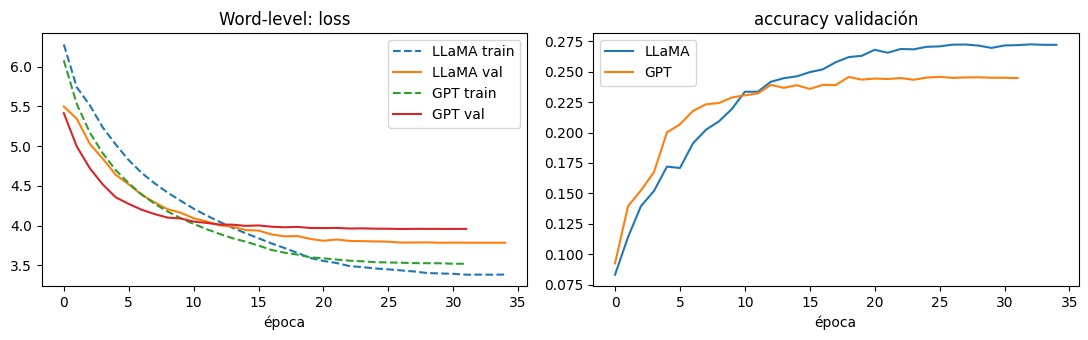

,val_loss_ep1,mejor_val_loss,mejor_epoca
LLaMA,5.491553,3.800025,29.000000
GPT,5.409116,3.954264,28.333333


In [12]:
curvas(runs_w, "Word-level", "curvas_word.png")
conv_w = convergencia(runs_w); conv_w.to_csv(SALIDAS / "convergencia_word.csv"); conv_w

### 5.3 Métricas en test
- **Perplejidad por palabra** y accuracy top‑1 / top‑5.
- **BPC equivalente** = bits totales / (tokens evaluados × caracteres reales por token). Permite una comparación *aproximada* con char-level, el BPC de palabra está subestimado.

In [13]:
unk_test = float(np.mean(np.concatenate([y for _, y in test_w.as_numpy_iterator()]) == 1))
res_w = {}
for k, lst in runs_w.items():
    rs = []
    for m, _ in lst:
        r = eval_lm(m, test_w)
        r["bpc_equiv"] = (r["nll_total"] / math.log(2)) / (r["n_tokens"] * CHARS_POR_TOKEN)
        r["params"] = m.count_params(); rs.append(r)
    res_w[k] = rs
df_w = pd.DataFrame({k: resumen(rs, ["params", "loss", "ppl", "bpc_equiv", "acc", "top5"]) for k, rs in res_w.items()}).T
df_w["n_semillas"] = P["n_seeds"]; df_w["pct_unk_test"] = round(100 * unk_test, 2)
df_w.to_csv(SALIDAS / "metricas_word.csv")
df_w.round(4)

,params,params_std,loss,loss_std,ppl,ppl_std,bpc_equiv,bpc_equiv_std,acc,acc_std,top5,top5_std,n_semillas,pct_unk_test
LLaMA,729382.0,0.0,3.9134,0.0284,50.0817,1.4252,0.9916,0.0072,0.2689,0.0046,0.5311,0.0034,3,10.01
GPT,787622.0,0.0,4.0452,0.0176,57.1262,1.0011,1.0250,0.0045,0.2456,0.0023,0.5117,0.0020,3,10.01


### 5.4 Generación y calidad del texto
En word-level se reporta **pct_unk** (tokens `<unk>` generados) en lugar de "palabras válidas" (que lo son por construcción) y **copia_4gram** para detectar memorización (p. ej. copiar nombres propios completos).

In [ ]:
def dec_w(ids):
    s = " ".join(vocab_w[i] for i in ids).replace(" <nl> ", "\n").replace("<nl>", "\n")
    return re.sub(r"\s+([.,;:!?)°])", r"\1", s)
def enc_w(s): return [w2i.get(w, 1) for w in tokenizar(s)]

prompt_w = "artículo 1°. colombia es un estado"      # igual que en el corpus: "1°." se tokeniza como 1, °, .
# Word-level: nunca muestrear <pad>/<unk> y penalizar repeticiones
df_gen_w = generar_y_medir(models_w, enc_w, dec_w, prompt_w, GEN["words"], LEN_W, "word", GEN["muestras"],
                           bloquear=(0, 1), rep_penalty=1.15)
df_gen_w.to_csv(SALIDAS / "generacion_word.csv", index=False)
df_gen_w


===== LLaMA | T=0.5 top_k=10 | muestra 1 de 3 =====
artículo 1°. colombia es un estado, con las leyes y las que le asignen la ley.
artículo transitorio 6°. los congresistas, y en la ley determinará el acceso a la ley.
artículo transitorio 3°. los miembros de la fuerza pública y el gobierno nacional, o en las entidades territoriales, la corte constitucional, mediante sentencia c - ep a la corte constitucional.
artículo transitorio 22. la corte suprema de justicia, m. p. luis guillermo guerrero pérez, declaró inexequible por el acto legislativo 2 de 2017, m. p. p. p. conocer de la constitución política, declaró inexequible el año siguiente.
el presidente de la república, la corte constitucional, mediante sentencia c - 674 de 2016, m. p. p. p. haber sido condenados por el acto legislativo 1 de 2015, m. p. luis guillermo guerrero pérez, declaró inexequible el inciso primero del artículo transitorio 1° del acto legislativo 1 de 1991.
artículo transitorio 1°. el gobierno nacional de la repú

,modelo,T,top_k,muestras,distinct1,distinct2,rep_3gram,copia_4gram,pct_unk
0,LLaMA,0.5,10.0,3,0.318,0.546,0.311,0.465,0.0
1,LLaMA,0.8,20.0,3,0.437,0.754,0.098,0.329,0.0
2,LLaMA,1.1,NaN,3,0.559,0.909,0.024,0.127,0.0
3,GPT,0.5,10.0,3,0.249,0.477,0.332,0.206,0.0
4,GPT,0.8,20.0,3,0.404,0.697,0.136,0.238,0.0
5,GPT,1.1,NaN,3,0.595,0.933,0.008,0.054,0.0


In [15]:
models_w["LLaMA"].save(SALIDAS / "word_llama_constitucion.keras")
json.dump(vocab_w, open(SALIDAS / "vocab_word.json", "w", encoding="utf-8"), ensure_ascii=False)

## 6. Comparación final
La comparación **char vs word** se presenta con cautela: el BPC de palabra depende de cómo se tratan los `<unk>` y de la tokenización.

In [16]:
print("=== LLaMA vs GPT (dentro de cada nivel, menor BPC = mejor) ===")
print("Char:", veredicto(res_c["LLaMA"], res_c["GPT"], "bpc"))
print("Word:", veredicto(res_w["LLaMA"], res_w["GPT"], "bpc_equiv"))
print("\nVelocidad de convergencia (val_loss tras la época 1):")
print("Char:", conv_c["val_loss_ep1"].round(3).to_dict(), "| Word:", conv_w["val_loss_ep1"].round(3).to_dict())

final = pd.DataFrame({
    "Char LLaMA": [df_c.loc["LLaMA", "bpc"], df_c.loc["LLaMA", "ppl"], df_c.loc["LLaMA", "acc"]],
    "Char GPT":   [df_c.loc["GPT",   "bpc"], df_c.loc["GPT",   "ppl"], df_c.loc["GPT",   "acc"]],
    "Word LLaMA": [df_w.loc["LLaMA", "bpc_equiv"], df_w.loc["LLaMA", "ppl"], df_w.loc["LLaMA", "acc"]],
    "Word GPT":   [df_w.loc["GPT",   "bpc_equiv"], df_w.loc["GPT",   "ppl"], df_w.loc["GPT",   "acc"]],
}, index=["BPC (word = INDICATIVO, no comparable)", "Perplejidad por token (NO comparable char vs word)", "Accuracy top-1"]).T
final.to_csv(SALIDAS / "comparacion_final.csv")
print(f"\n(% de <unk> en test a nivel de palabra: {100*unk_test:.2f}% → el BPC de palabra está algo subestimado)")
final.round(3)

=== LLaMA vs GPT (dentro de cada nivel, menor BPC = mejor) ===
Char: EMPATE técnico (LLaMA 1.254 vs GPT 1.247; dif. 0.6% ≤ umbral de ruido)
Word: LLaMA es mejor (0.992 vs 1.025; dif. 3.3%)

Velocidad de convergencia (val_loss tras la época 1):
Char: {'LLaMA': 2.058, 'GPT': 2.714} | Word: {'LLaMA': 5.492, 'GPT': 5.409}

(% de <unk> en test a nivel de palabra: 10.01% → el BPC de palabra está algo subestimado)


,"BPC (word = INDICATIVO, no comparable)",Perplejidad por token (NO comparable char vs word),Accuracy top-1
Char LLaMA,1.254,2.385,0.740
Char GPT,1.247,2.373,0.740
Word LLaMA,0.992,50.082,0.269
Word GPT,1.025,57.126,0.246


### Conclusiones
La siguiente celda **redacta un borrador con los números de tu corrida** (se actualiza sola si repites el entrenamiento). Cópialo al informe y completa la interpretación con tus palabras.

In [17]:
def pm(df, fila, col):
    """'media ± std' si hay varias semillas; si no, solo la media."""
    m, sd = df.loc[fila, col], df.loc[fila, col + "_std"]
    return f"{m:.3f}" + (f" ± {sd:.3f}" if pd.notna(sd) else "")

def borrador_conclusiones():
    ns = P["n_seeds"]
    print(f"BORRADOR DE CONCLUSIONES — perfil {PERFIL}, {ns} semilla(s) por modelo\n")
    print("1) CHAR-LEVEL")
    print(f"   - BPC en test: LLaMA {pm(df_c,'LLaMA','bpc')} vs GPT {pm(df_c,'GPT','bpc')} → {veredicto(res_c['LLaMA'], res_c['GPT'], 'bpc')}.")
    print(f"   - Accuracy top-1 / top-5 (LLaMA): {df_c.loc['LLaMA','acc']*100:.1f} % / {df_c.loc['LLaMA','top5']*100:.1f} %. Parámetros: LLaMA {int(df_c.loc['LLaMA','params']):,} vs GPT {int(df_c.loc['GPT','params']):,}.")
    print(f"   - Convergencia: val_loss tras la época 1 → LLaMA {conv_c.loc['LLaMA','val_loss_ep1']:.2f} vs GPT {conv_c.loc['GPT','val_loss_ep1']:.2f}; mejor época media {conv_c.loc['LLaMA','mejor_epoca']:.0f} (LLaMA) y {conv_c.loc['GPT','mejor_epoca']:.0f} (GPT) de {C['epochs']} posibles"
          + (" → aún podían mejorar con más épocas." if conv_c['mejor_epoca'].max() >= C['epochs'] - 0.5 else " → el early stopping se activó."))
    ppe = C["len"] / C["shift"]
    print(f"   - Ojo con las 'épocas': con len={C['len']} y shift={C['shift']}, cada época son ≈ {ppe:.0f} pasadas por el corpus; la mejor época de LLaMA ({conv_c.loc['LLaMA','mejor_epoca']:.0f}) equivale a ≈ {conv_c.loc['LLaMA','mejor_epoca']*ppe:.0f} pasadas efectivas (si es muy alto, el modelo ya memoriza: ver copia_4gram).")
    g = df_gen_c[df_gen_c.modelo == "LLaMA"].set_index("T")
    print(f"   - Texto (LLaMA): palabras válidas {g.loc[0.5,'palabras_validas']*100:.0f} % con T=0.5 y {g.loc[1.1,'palabras_validas']*100:.0f} % con T=1.1; copia literal de 4-gramas {g.loc[0.5,'copia_4gram']*100:.0f} % (T=0.5) vs {g.loc[1.1,'copia_4gram']*100:.0f} % (T=1.1): más temperatura = menos memorización, más palabras inventadas.")
    print("\n2) WORD-LEVEL")
    print(f"   - Perplejidad en test: LLaMA {pm(df_w,'LLaMA','ppl')} vs GPT {pm(df_w,'GPT','ppl')} → {veredicto(res_w['LLaMA'], res_w['GPT'], 'ppl')}.")
    print(f"   - Accuracy top-1: LLaMA {df_w.loc['LLaMA','acc']*100:.1f} %, GPT {df_w.loc['GPT','acc']*100:.1f} %. Vocabulario {V} palabras; {df_w['pct_unk_test'].iloc[0]:.1f} % de los tokens de test son <unk>.")
    print(f"   - Sobreajuste: mejor época {conv_w.loc['LLaMA','mejor_epoca']:.0f} (LLaMA) y {conv_w.loc['GPT','mejor_epoca']:.0f} (GPT) de {W['epochs']}; con ~{len(tokens)//1000} mil tokens el modelo memoriza rápido (early stopping restaura los mejores pesos).")
    ppw = W["len"] / W["shift"]
    print(f"   - Pasadas por época: ≈ {ppw:.0f}; mejor época de LLaMA {conv_w.loc['LLaMA','mejor_epoca']:.0f} ≈ {conv_w.loc['LLaMA','mejor_epoca']*ppw:.0f} pasadas efectivas.")
    gw = df_gen_w[df_gen_w.modelo == "LLaMA"].set_index("T")
    print(f"   - Texto (LLaMA): copia literal de 4-gramas {gw.loc[0.5,'copia_4gram']*100:.0f} % (T=0.5) vs {gw.loc[1.1,'copia_4gram']*100:.0f} % (T=1.1); tokens <unk> generados {gw.loc[0.5,'pct_unk']*100:.0f} %.")
    print("\n3) CHAR VS WORD")
    print(f"   - BPC indicativo: char {df_c.loc['LLaMA','bpc']:.2f} vs word {df_w.loc['LLaMA','bpc_equiv']:.2f}. NO se concluye que 'palabra sea mejor': los <unk> abaratan la predicción y la tokenización cambia la tarea.")
    print("\n4) METODOLOGÍA Y LIMITACIONES")
    print("   - Split por bloques intercalados (test representativo), vocabulario solo con train, texto en minúsculas con Python.")
    print("   - Corpus pequeño (~455 mil caracteres), sin KV-cache al generar, sin subpalabras (BPE), modelos pequeños.")
borrador_conclusiones()

BORRADOR DE CONCLUSIONES — perfil gpu, 3 semilla(s) por modelo

1) CHAR-LEVEL
   - BPC en test: LLaMA 1.254 ± 0.003 vs GPT 1.247 ± 0.006 → EMPATE técnico (LLaMA 1.254 vs GPT 1.247; dif. 0.6% ≤ umbral de ruido).
   - Accuracy top-1 / top-5 (LLaMA): 74.0 % / 93.7 %. Parámetros: LLaMA 1,598,462 vs GPT 1,828,286.
   - Convergencia: val_loss tras la época 1 → LLaMA 2.06 vs GPT 2.71; mejor época media 34 (LLaMA) y 46 (GPT) de 60 posibles → el early stopping se activó.
   - Ojo con las 'épocas': con len=128 y shift=32, cada época son ≈ 4 pasadas por el corpus; la mejor época de LLaMA (34) equivale a ≈ 136 pasadas efectivas (si es muy alto, el modelo ya memoriza: ver copia_4gram).
   - Texto (LLaMA): palabras válidas 100 % con T=0.5 y 96 % con T=1.1; copia literal de 4-gramas 37 % (T=0.5) vs 11 % (T=1.1): más temperatura = menos memorización, más palabras inventadas.

2) WORD-LEVEL
   - Perplejidad en test: LLaMA 50.082 ± 1.425 vs GPT 57.126 ± 1.001 → LLaMA es mejor (50.082 vs 57.126; dif. 12.